# Course 10: Deep Learning on Curved Spaces
## Session 8: Hyperbolic neural networks

**Goal:** build hyperbolic layers from exp/log maps and Möbius operations and check them numerically, test graphs for tree-likeness with Gromov's δ, and compare a hyperbolic MLP with a Euclidean MLP of the same size on data whose labels follow a tree.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Layers in the Poincaré ball
We use the Poincaré ball of curvature $-c$, $\{x : c\|x\|^2 < 1\}$, with conformal factor $\lambda_x = 2/(1 - c\|x\|^2)$ (session 6). The operations of Ganea et al. (2018):

* Möbius addition: $x \oplus_c y = \dfrac{(1 + 2c\langle x, y\rangle + c\|y\|^2)\,x + (1 - c\|x\|^2)\,y}{1 + 2c\langle x, y\rangle + c^2\|x\|^2\|y\|^2}$;
* maps at the origin: $\exp_0(v) = \tanh(\sqrt c\|v\|)\dfrac{v}{\sqrt c\|v\|}$ and $\log_0(y) = \operatorname{artanh}(\sqrt c\|y\|)\dfrac{y}{\sqrt c\|y\|}$; at a point $x$, $\exp_x(v) = x \oplus_c \tanh\!\big(\sqrt c\,\lambda_x\|v\|/2\big)\dfrac{v}{\sqrt c\|v\|}$;
* Möbius matrix–vector product: $M \otimes_c x = \exp_0(M\log_0(x)) = \dfrac{1}{\sqrt c}\tanh\!\Big(\dfrac{\|Mx\|}{\|x\|}\operatorname{artanh}(\sqrt c\|x\|)\Big)\dfrac{Mx}{\|Mx\|}$;
* a layer: $h = \sigma^{\otimes}\big((M \otimes_c x) \oplus_c b\big)$, where $\sigma^{\otimes}(x) = \exp_0(\sigma(\log_0 x))$ applies a nonlinearity in the tangent space at 0;
* hyperbolic multinomial logistic regression (MLR): the logit of class $k$ is
  $$\frac{\lambda_{p_k}\|a_k\|}{\sqrt c}\operatorname{arsinh}\!\left(\frac{2\sqrt c\,\langle(-p_k) \oplus_c x,\ a_k\rangle}{(1 - c\|(-p_k) \oplus_c x\|^2)\,\|a_k\|}\right),$$
  which is $\lambda_{p_k}\|a_k\|$ times the **signed distance** from $x$ to the "gyroplane" through $p_k$ orthogonal to $a_k$. As $c \to 0$ it becomes $4\langle x - p_k, a_k\rangle$, ordinary MLR up to a factor of 4.

The cell checks each claim: the closed form of $M \otimes_c x$ against $\exp_0(M\log_0 x)$; $(NM) \otimes_c x = N \otimes_c (M \otimes_c x)$; that $x \oplus y$ and $y \oplus x$ differ but have the same norm; the limits as $c \to 0$; and the gyroplane distance against a brute-force search along the gyroplane, which in 2-D is the geodesic through $p$ orthogonal to $a$. It also checks a faster matrix form of the MLR that we use for training.

In [1]:
import time, itertools
import numpy as np
import networkx as nx
import torch
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression

t_start = time.time()
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
np.random.seed(0); torch.manual_seed(0)

def mobius_add(x, y, c):
    xy, x2, y2 = (x * y).sum(-1, keepdim=True), (x * x).sum(-1, keepdim=True), (y * y).sum(-1, keepdim=True)
    return ((1 + 2 * c * xy + c * y2) * x + (1 - c * x2) * y) / (1 + 2 * c * xy + c**2 * x2 * y2)

def expmap0(v, c):
    n = v.norm(dim=-1, keepdim=True).clamp_min(1e-15)
    return torch.tanh(c**0.5 * n) * v / (c**0.5 * n)

def logmap0(y, c):
    n = y.norm(dim=-1, keepdim=True).clamp_min(1e-15)
    return torch.atanh((c**0.5 * n).clamp(max=1 - 1e-15)) * y / (c**0.5 * n)

def expmap(x, v, c):
    lam = 2 / (1 - c * (x * x).sum(-1, keepdim=True))
    n = v.norm(dim=-1, keepdim=True).clamp_min(1e-15)
    return mobius_add(x, torch.tanh(c**0.5 * lam * n / 2) * v / (c**0.5 * n), c)

def mobius_matvec(M, x, c):                                   # M has shape (out, in)
    Mx = x @ M.T
    xn, Mxn = x.norm(dim=-1, keepdim=True).clamp_min(1e-15), Mx.norm(dim=-1, keepdim=True).clamp_min(1e-15)
    return torch.tanh(Mxn / xn * torch.atanh((c**0.5 * xn).clamp(max=1 - 1e-15))) * Mx / (c**0.5 * Mxn)

def dist(x, y, c):
    return 2 / c**0.5 * torch.atanh((c**0.5 * mobius_add(-x, y, c).norm(dim=-1)).clamp(max=1 - 1e-15))

def mlr_direct(x, p, a, c):                                   # x (N, d); p, a (K, d)
    mx = mobius_add(-p[None], x[:, None, :], c)
    lam = 2 / (1 - c * (p * p).sum(-1))
    an = a.norm(dim=-1)
    return lam * an / c**0.5 * torch.asinh(2 * c**0.5 * (mx * a[None]).sum(-1) / ((1 - c * (mx * mx).sum(-1)) * an))

def mlr(x, p, a, c):                                          # the same, from inner products only (faster)
    xp, xa, x2 = x @ p.T, x @ a.T, (x * x).sum(-1, keepdim=True)
    pa, p2 = (p * a).sum(-1), (p * p).sum(-1)
    alpha, beta = 1 - 2 * c * xp + c * x2, 1 - c * p2         # (-p) + x = (alpha (-p) + beta x) / den
    den = 1 - 2 * c * xp + c**2 * p2 * x2
    dot_a = (-alpha * pa + beta * xa) / den
    norm2 = (alpha**2 * p2 - 2 * alpha * beta * xp + beta**2 * x2) / den**2
    an = a.norm(dim=-1)
    return 2 / (1 - c * p2) * an / c**0.5 * torch.asinh(2 * c**0.5 * dot_a / ((1 - c * norm2) * an))

g = torch.Generator().manual_seed(0)
for c in [1.0, 0.3]:
    x, y = expmap0(torch.randn(200, 3, generator=g) * 0.8, c), expmap0(torch.randn(200, 3, generator=g) * 0.8, c)
    M, N = torch.randn(4, 3, generator=g), torch.randn(3, 4, generator=g)
    print(f"c = {c}: closed form vs exp0(M log0 x) {(mobius_matvec(M, x, c) - expmap0(logmap0(x, c) @ M.T, c)).abs().max():.1e}; "
          f"(NM)x vs N(Mx) {(mobius_matvec(N @ M, x, c) - mobius_matvec(N, mobius_matvec(M, x, c), c)).abs().max():.1e}; "
          f"x+y vs y+x: largest gap {(mobius_add(x, y, c) - mobius_add(y, x, c)).abs().max():.2f}, "
          f"norms differ by {(mobius_add(x, y, c).norm(dim=-1) - mobius_add(y, x, c).norm(dim=-1)).abs().max():.1e}")
x, y, M = torch.randn(5, 3, generator=g) * 0.5, torch.randn(5, 3, generator=g) * 0.5, torch.randn(4, 3, generator=g)
p, a = torch.randn(4, 3, generator=g) * 0.3, torch.randn(4, 3, generator=g)
print(f"c = 1e-8: M(x) - Mx {(mobius_matvec(M, x, 1e-8) - x @ M.T).abs().max():.1e}; x+y - (x + y) {(mobius_add(x, y, 1e-8) - (x + y)).abs().max():.1e}; "
      f"MLR - 4<x - p, a> {(mlr(x, p, a, 1e-8) - 4 * ((x[:, None] - p[None]) * a[None]).sum(-1)).abs().max():.1e}")

errs = []                                                     # brute force: distance to the gyroplane in 2-D, c = 1
for trial in range(3):
    p, a = expmap0(torch.randn(1, 2, generator=g) * 0.7, 1.0), torch.randn(1, 2, generator=g)
    u = torch.stack([-a[:, 1], a[:, 0]], -1); u = u / u.norm()          # direction of the gyroplane at p
    lam = (2 / (1 - (p * p).sum())).item()
    xs = expmap0(torch.randn(5, 2, generator=g), 1.0)
    signed = mlr(xs, p, a, 1.0)[:, 0] / (lam * a.norm())
    ts = torch.linspace(-12, 12, 4001)[:, None] / lam                    # walk up to distance 12 each way
    line = expmap(p.expand(len(ts), 2), ts * u, 1.0)
    for i in range(5):
        k = int(dist(xs[i:i + 1].expand(len(ts), 2), line, 1.0).argmin()); h = 24 / lam / 4000
        f = lambda t: dist(xs[i:i + 1], expmap(p, torch.tensor([[t]]) * u, 1.0), 1.0).item()
        best = minimize_scalar(f, bounds=(ts[k, 0].item() - h, ts[k, 0].item() + h), method="bounded", options={"xatol": 1e-13})
        errs.append(abs(abs(signed[i].item()) - best.fun))
print(f"gyroplane distance, closed form vs brute force (15 points): largest difference {max(errs):.1e}")
x, p, a = expmap0(torch.randn(50, 4, generator=g) * 0.5, 1.0), expmap0(torch.randn(7, 4, generator=g) * 0.5, 1.0), torch.randn(7, 4, generator=g)
print(f"fast MLR vs direct MLR: largest relative difference {((mlr(x, p, a, 1.0) - mlr_direct(x, p, a, 1.0)).abs() / mlr_direct(x, p, a, 1.0).abs().clamp_min(1)).max():.1e}")

c = 1.0: closed form vs exp0(M log0 x) 2.2e-16; (NM)x vs N(Mx) 4.4e-15; x+y vs y+x: largest gap 1.51, norms differ by 4.4e-16
c = 0.3: closed form vs exp0(M log0 x) 6.7e-16; (NM)x vs N(Mx) 6.7e-16; x+y vs y+x: largest gap 2.15, norms differ by 2.2e-15
c = 1e-8: M(x) - Mx 1.9e-07; x+y - (x + y) 2.9e-08; MLR - 4<x - p, a> 3.3e-07
gyroplane distance, closed form vs brute force (15 points): largest difference 2.9e-14
fast MLR vs direct MLR: largest relative difference 1.4e-14


### 2. Is a graph tree-like? Gromov's four-point δ
For four nodes $x, y, z, w$ there are three ways to split them into two pairs. Add the two distances in each split and sort the three sums, $S_1 \ge S_2 \ge S_3$. The four-point value is $\delta(x, y, z, w) = (S_1 - S_2)/2$, and the graph's $\delta$ is the largest value over all quadruples (Gromov 1987). In a tree the two largest sums are always equal, so $\delta = 0$. The triangle inequality gives $\delta \le \text{diameter}/2$ for every graph, so $2\delta/\text{diameter}$ lies between 0 (a tree) and 1, and lets us compare graphs of different sizes.

We sample 200,000 random quadruples, which gives a **lower bound** on $\delta$, for a tree, a grid, a random graph, a small-world graph and a cycle, all of comparable size.

In [2]:
def shortest_paths(G):
    idx = {v: i for i, v in enumerate(G)}
    D = np.zeros((len(idx), len(idx)))
    for u, row in nx.all_pairs_shortest_path_length(G):
        for v, l in row.items():
            D[idx[u], idx[v]] = l
    return D

def four_point(D, q):                                         # q: array of quadruples, shape (m, 4)
    x, y, z, w = q.T
    S = np.sort(np.stack([D[x, y] + D[z, w], D[x, z] + D[y, w], D[x, w] + D[y, z]]), axis=0)
    return (S[2] - S[1]) / 2

rng = np.random.default_rng(0)
graphs = {"tree (3 children, depth 4)": nx.balanced_tree(3, 4),
          "grid 11 x 11": nx.grid_2d_graph(11, 11),
          "random graph (Erdos-Renyi, p = 0.04)": nx.gnp_random_graph(121, 0.04, seed=0),
          "small world (Watts-Strogatz, k = 4, p = 0.1)": nx.connected_watts_strogatz_graph(121, 4, 0.1, seed=0),
          "cycle of 40 nodes": nx.cycle_graph(40)}
print("graph                                          nodes  edges  diameter  delta  2 delta/diameter")
for name, G in graphs.items():
    assert nx.is_connected(G)
    D = shortest_paths(G)
    dl = four_point(D, rng.integers(0, len(D), (200_000, 4)))
    print(f"{name:45s} {len(D):6d} {G.number_of_edges():6d} {int(D.max()):9d} {dl.max():6.1f} {2 * dl.max() / D.max():12.3f}")

graph                                          nodes  edges  diameter  delta  2 delta/diameter
tree (3 children, depth 4)                       121    120         8    0.0        0.000
grid 11 x 11                                     121    220        20    8.0        0.800
random graph (Erdos-Renyi, p = 0.04)             121    308         6    2.0        0.667
small world (Watts-Strogatz, k = 4, p = 0.1)     121    242        10    4.0        0.800


cycle of 40 nodes                                 40     40        20   10.0        1.000


### 3. Synthetic data whose labels follow a tree
A **synthetic** stand-in for hierarchical labels (species within genera within families, or fine classes within superclasses): a class tree with branching 3 and depth 3 has 27 leaf classes. Every non-root node of the class tree gets a random vector in $\mathbb{R}^{20}$, of scale 2, 1 and 0.5 at depths 1, 2 and 3. A class mean is the sum of the vectors on its path from the root, and each example is its class mean plus Gaussian noise with standard deviation 1. Sibling classes are close, cousins farther apart, and classes in different top-level branches far apart. There are 60 training and 60 test examples per class.

The class means themselves form a fairly tree-like set of points: the cell computes their four-point $\delta$ exactly (all 17,550 quadruples) and compares it with 27 random Gaussian points. Logistic regression on the raw 20 inputs, with no bottleneck, gives a reference accuracy. Besides accuracy we report **parent accuracy**: whether the predicted class is in the right group of three siblings, which measures how bad the mistakes are.

In [3]:
Tc = nx.balanced_tree(3, 3)
parent_c = {v: u for u, v in nx.bfs_edges(Tc, 0)}
depth_c = nx.shortest_path_length(Tc, 0)
leaves = sorted(v for v in Tc if Tc.degree(v) == 1)
K, Din = len(leaves), 20
par = np.array([parent_c[l] for l in leaves])

rng = np.random.default_rng(0)
vec = {v: rng.normal(0, [2.0, 1.0, 0.5][depth_c[v] - 1], Din) for v in Tc if v != 0}
means = np.zeros((K, Din))
for k, l in enumerate(leaves):
    v = l
    while v != 0:
        means[k] += vec[v]; v = parent_c[v]
ytr = np.repeat(np.arange(K), 60); yte = ytr.copy()
Xtr = means[ytr] + rng.normal(0, 1.0, (len(ytr), Din))
Xte = means[yte] + rng.normal(0, 1.0, (len(yte), Din))
mu, sd = Xtr.mean(0), Xtr.std(0)
Xtr_t, Xte_t = torch.tensor((Xtr - mu) / sd), torch.tensor((Xte - mu) / sd)
ytr_t = torch.tensor(ytr)
print(f"{K} classes, {len(ytr)} training and {len(yte)} test examples, {Din} features")

quads = np.array(list(itertools.combinations(range(K), 4)))
for name, P in [("class means", means), ("27 random Gaussian points", np.random.default_rng(5).normal(0, means.std(), (K, Din)))]:
    Dm = np.sqrt(((P[:, None] - P[None]) ** 2).sum(-1))
    print(f"{name}: delta = {four_point(Dm, quads).max():.2f}, 2 delta/diameter = {2 * four_point(Dm, quads).max() / Dm.max():.3f}")

lr_raw = LogisticRegression(max_iter=3000).fit(Xtr, ytr)
pred = lr_raw.predict(Xte)
print(f"reference, logistic regression on the 20 raw features: test accuracy {np.mean(pred == yte):.3f}, parent accuracy {np.mean(par[pred] == par[yte]):.3f}")

27 classes, 1620 training and 1620 test examples, 20 features
class means: delta = 2.40, 2 delta/diameter = 0.278
27 random Gaussian points: delta = 3.72, 2 delta/diameter = 0.411


reference, logistic regression on the 20 raw features: test accuracy 0.829, parent accuracy 0.991


### 4. A Euclidean and a hyperbolic MLP with the same number of parameters
Both models start with the same Euclidean layer, $v = \text{ReLU}(W_1 x + b_1)$ of width 64, followed by a bottleneck of dimension $d \in \{2, 5, 10\}$ in which classification happens:

* **Euclidean:** $h = W_2 v + b_2 \in \mathbb{R}^d$ and logits $\langle h - p_k, a_k\rangle$. This Euclidean MLR, written with a point $p_k$ and a normal $a_k$ per class, is the $c \to 0$ limit of the hyperbolic one and has the same number of parameters. As a function it is an ordinary linear layer, so some of its parameters are redundant.
* **Hyperbolic** ($c = 1$): $z = \exp_0(v) \in \mathbb{B}^{64}$, then $h = (W_2 \otimes_c z) \oplus_c \exp_0(b_2) \in \mathbb{B}^d$ and the hyperbolic MLR, with $p_k = \exp_0(p'_k)$ and $a_k = (1 - c\|p_k\|^2)\,a'_k$, the parallel transport of $a'_k$ from 0 to $p_k$ (as in Ganea et al. 2018). Every trainable parameter is then Euclidean, so plain Adam works; Ganea et al. moved the ball points with Riemannian SGD instead.
* **A cap on the tangent vector.** ReLU features have norms of several units, and $\exp_0$ of such a vector lies within about $10^{-6}$ of the boundary of $\mathbb{B}^{64}$, where tanh saturates and gradients vanish. So by default we rescale $v$ to norm at most 1 before $\exp_0$. To see why, the hyperbolic model at $d = 2$ is also trained without the cap.

Both models use Adam with learning rate 0.01, 300 full-batch epochs and three seeds per setting. Each run also reports its training accuracy and its time: every hyperbolic layer costs extra maps between the ball and the tangent space.

In [4]:
H = 64
class EuclideanMLP(torch.nn.Module):
    def __init__(self, d):
        super().__init__()
        self.l1, self.l2 = torch.nn.Linear(Din, H), torch.nn.Linear(H, d)
        self.P, self.A = torch.nn.Parameter(torch.randn(K, d) * 0.01), torch.nn.Parameter(torch.randn(K, d) / d**0.5)
    def forward(self, x):
        h = self.l2(torch.relu(self.l1(x)))
        return h @ self.A.T - (self.P * self.A).sum(-1)       # <h - p_k, a_k>

class HyperbolicMLP(torch.nn.Module):
    def __init__(self, d, c=1.0, cap=1.0):
        super().__init__()
        self.c, self.cap = c, cap
        self.l1 = torch.nn.Linear(Din, H)
        self.W, self.b = torch.nn.Parameter(torch.randn(d, H) / H**0.5), torch.nn.Parameter(torch.zeros(d))
        self.P, self.A = torch.nn.Parameter(torch.randn(K, d) * 0.01), torch.nn.Parameter(torch.randn(K, d) / d**0.5)
    def forward(self, x):
        v = torch.relu(self.l1(x))
        if self.cap is not None:
            v = v * torch.clamp(self.cap / v.norm(dim=-1, keepdim=True).clamp_min(1e-15), max=1.0)
        h = mobius_add(mobius_matvec(self.W, expmap0(v, self.c), self.c), expmap0(self.b, self.c), self.c)
        p = expmap0(self.P, self.c)
        return mlr(h, p, self.A * (1 - self.c * (p * p).sum(-1, keepdim=True)), self.c)

def run(model, seed, epochs=300, lr=1e-2):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    t0 = time.time()
    for ep in range(epochs):
        loss = torch.nn.functional.cross_entropy(model(Xtr_t), ytr_t)
        if not torch.isfinite(loss):
            return dict(failed=ep, time=time.time() - t0)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        pred, ptr = model(Xte_t).argmax(1).numpy(), model(Xtr_t).argmax(1).numpy()
    return dict(failed=None, test=np.mean(pred == yte), parent=np.mean(par[pred] == par[yte]), train=np.mean(ptr == ytr), time=time.time() - t0)

results = {}
settings = [(d, kind, cap) for d in [2, 5, 10] for kind, cap in [("Euclidean", None), ("hyperbolic", 1.0)]] + [(2, "hyperbolic", None)]
for d, kind, cap in settings:
    rs = []
    for seed in range(3):
        torch.manual_seed(seed)
        model = EuclideanMLP(d) if kind == "Euclidean" else HyperbolicMLP(d, cap=cap)
        rs.append(run(model, seed) | {"params": sum(q.numel() for q in model.parameters())})
    results[(d, kind, cap)] = rs

print("d   model                     params  test accuracy     parent accuracy   train accuracy   s per run")
for (d, kind, cap), rs in results.items():
    ok = [r for r in rs if r["failed"] is None]
    label = kind + ("" if kind == "Euclidean" else (", cap 1" if cap else ", no cap"))
    m = lambda key: (np.mean([r[key] for r in ok]), np.std([r[key] for r in ok], ddof=1) if len(ok) > 1 else 0.0)
    line = f"{d:2d}  {label:24s} {rs[0]['params']:6d}  {m('test')[0]:.3f} +- {m('test')[1]:.3f}    {m('parent')[0]:.3f} +- {m('parent')[1]:.3f}    {m('train')[0]:.3f}            {np.mean([r['time'] for r in rs]):.1f}"
    fails = [f"seed {i} gave a non-finite loss at epoch {r['failed']}" for i, r in enumerate(rs) if r["failed"] is not None]
    print(line + ("" if not fails else f"   ({len(ok)} of 3 seeds; " + "; ".join(fails) + ")"))
    if cap is None and kind == "hyperbolic":
        print("    test accuracy of each finished seed:", [round(float(r["test"]), 3) for r in ok])

d   model                     params  test accuracy     parent accuracy   train accuracy   s per run
 2  Euclidean                  1582  0.627 +- 0.022    0.915 +- 0.026    0.860            0.6
 2  hyperbolic, cap 1          1582  0.595 +- 0.018    0.927 +- 0.015    0.921            3.0
 5  Euclidean                  1939  0.781 +- 0.006    0.977 +- 0.005    1.000            0.6
 5  hyperbolic, cap 1          1939  0.759 +- 0.015    0.966 +- 0.009    0.999            3.0
10  Euclidean                  2534  0.802 +- 0.003    0.974 +- 0.002    1.000            0.6
10  hyperbolic, cap 1          2534  0.783 +- 0.003    0.974 +- 0.002    1.000            3.0
 2  hyperbolic, no cap         1582  0.568 +- 0.015    0.923 +- 0.008    0.720            2.4   (2 of 3 seeds; seed 2 gave a non-finite loss at epoch 230)
    test accuracy of each finished seed: [0.557, 0.578]


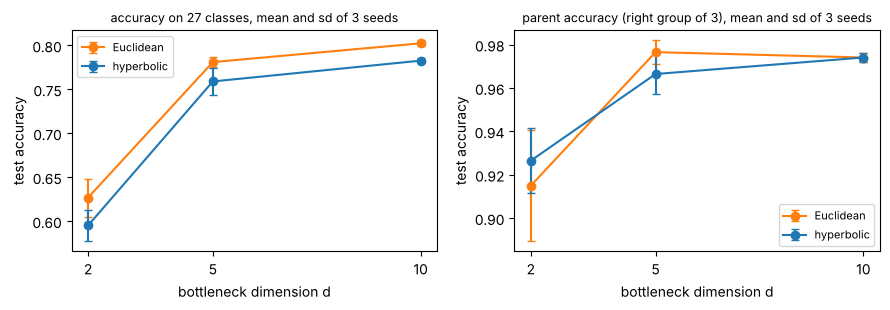

runtime so far 43 s


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for kind, cap, col in [("Euclidean", None, "C1"), ("hyperbolic", 1.0, "C0")]:
    for k, key in enumerate(["test", "parent"]):
        vals = np.array([[r[key] for r in results[(d, kind, cap)]] for d in [2, 5, 10]])
        ax[k].errorbar([2, 5, 10], vals.mean(1), yerr=vals.std(1, ddof=1), marker="o", capsize=3, color=col, label=kind)
for k, title in enumerate(["accuracy on 27 classes", "parent accuracy (right group of 3)"]):
    ax[k].set_xlabel("bottleneck dimension d"); ax[k].set_ylabel("test accuracy"); ax[k].set_xticks([2, 5, 10])
    ax[k].set_title(title + ", mean and sd of 3 seeds", fontsize=9); ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 5. The same operations in a library (NOT RUN here)
geoopt (Kochurov et al. 2020) implements the Poincaré ball and Riemannian optimizers in PyTorch. Comparing your functions with a library's is a cheap test. HGCN's official code builds graph layers from the same operations.

In [ ]:
# NOT RUN: needs geoopt (pip install geoopt)
import geoopt
ball = geoopt.PoincareBall(c=1.0)
x = ball.expmap0(torch.randn(5, 3) * 0.5)
y = ball.expmap0(torch.randn(5, 3) * 0.5)
M = torch.randn(4, 3)
print("Mobius addition:", (ball.mobius_add(x, y) - mobius_add(x, y, 1.0)).abs().max().item())
print("Mobius matrix-vector product:", (ball.mobius_matvec(M, x) - mobius_matvec(M, x, 1.0)).abs().max().item())
print("distance:", (ball.dist(x, y) - dist(x, y, 1.0)).abs().max().item())
print("log map at 0:", (ball.logmap0(x) - logmap0(x, 1.0)).abs().max().item())

### 6. Exercises

In [6]:
# TODO: trainable curvature, as in HGCN (Chami et al. 2019). Give HyperbolicMLP a parameter rho and use
# c = softplus(rho) (starting at c = 1) everywhere the model uses self.c. Train at d = 2 for three seeds and
# return (mean test accuracy, list of learned c). Does the model move towards flat (small c) or more curved space?
def trainable_curvature():
    return None          # replace with your code

r = trainable_curvature()
print("not done yet" if r is None else r)

not done yet


In [7]:
# TODO: exact delta. Sampling gives only a lower bound. For a 6 x 6 grid and the cycle of 40 nodes, compute delta
# exactly over all quadruples (use itertools.combinations and four_point in chunks), and compare with the value
# from 200,000 random quadruples. Return a dictionary {graph name: (exact, sampled)}.
def exact_delta():
    return None          # replace with your code

r = exact_delta()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds, except the timings.)

1. **The formulas check out.** The closed form of $M \otimes_c x$ matched $\exp_0(M\log_0 x)$ to 2.2e-16 ($c = 1$) and 6.7e-16 ($c = 0.3$), and $(NM) \otimes_c x = N \otimes_c (M \otimes_c x)$ held to 4.4e-15. $x \oplus y$ and $y \oplus x$ differed by up to 1.51 but had the same norm (to 4.4e-16). With $c = 10^{-8}$ the operations matched their Euclidean versions to within 3.3e-07, an error of order $c$. The hyperbolic MLR's signed distance matched a brute-force search along the gyroplane to 2.9e-14, and the fast MLR matched the direct one to a relative 1.4e-14.
2. **δ separates trees from the rest.** Relative to the diameter, $2\delta/\text{diam}$ was 0.000 for the tree, 0.667 for the random graph, 0.800 for both the grid and the small-world graph, and 1.000 for the cycle. The random graph has the smallest absolute $\delta$ after the tree (2.0) only because its diameter is small (6): compare graphs with the relative value. The class means of our data gave 0.278, against 0.411 for random Gaussian points: tree-like, but not a tree.
3. **The Euclidean MLP won, at every dimension, against the expectation.** Test accuracy was 0.627 against 0.595 at $d = 2$, 0.781 against 0.759 at $d = 5$ and 0.802 against 0.783 at $d = 10$ (means of 3 seeds, same parameter counts). At $d = 2$ the hyperbolic model fitted the training data better (0.921 against 0.860) but generalized worse, and its parent accuracy was a little higher (0.927 against 0.915, within the seed-to-seed spread). This is one small synthetic task with untuned settings, so it does not show that hyperbolic networks never help; it shows that tree-shaped labels alone did not make them help here.
4. **Hyperbolic layers cost time and need care.** A hyperbolic run took about 3 s against about 0.6 s for the Euclidean one, roughly five times longer (timings vary from run to run). Without the cap on the tangent vector, training accuracy at $d = 2$ fell to 0.720, the finished seeds reached only 0.557 and 0.578, and one of three seeds produced a non-finite loss at epoch 230.
5. **Check the simplest baseline too.** Logistic regression on the 20 raw features reached 0.829, above every bottleneck model: with 1,620 training examples, the bottleneck and the extra layers did not pay off for either geometry.